# HOFLON improvement phase 1 #

- replace critic as nn 
- attempt to explore the optimisation objective 
- introduce offline RL ideas into optimisation objective or critic objective 
- introduce sarsa protocol to crtiic training 


## setting up the og hoflon protocol ## 

In [1]:
from poly_reactor_hoflon import train_hoflon

training_result = train_hoflon(
    dataset_path="pid_dataset.csv",
    output_dir="hoflon_og",
    device="cuda",
)

AAE epoch   1/500 | recon MSE=0.347422 | adv=0.6995
AAE epoch   2/500 | recon MSE=0.318617 | adv=0.6992
AAE epoch   3/500 | recon MSE=0.292727 | adv=0.6978
AAE epoch   4/500 | recon MSE=0.270502 | adv=0.6967
AAE epoch   5/500 | recon MSE=0.249646 | adv=0.6963
AAE epoch   6/500 | recon MSE=0.229279 | adv=0.6965
AAE epoch   7/500 | recon MSE=0.208981 | adv=0.6969
AAE epoch   8/500 | recon MSE=0.189001 | adv=0.6974
AAE epoch   9/500 | recon MSE=0.169771 | adv=0.6979
AAE epoch  10/500 | recon MSE=0.151726 | adv=0.6982
AAE epoch  11/500 | recon MSE=0.135149 | adv=0.6984
AAE epoch  12/500 | recon MSE=0.120261 | adv=0.6986
AAE epoch  13/500 | recon MSE=0.107190 | adv=0.6986
AAE epoch  14/500 | recon MSE=0.095916 | adv=0.6984
AAE epoch  15/500 | recon MSE=0.086381 | adv=0.6981
AAE epoch  16/500 | recon MSE=0.078425 | adv=0.6976
AAE epoch  17/500 | recon MSE=0.071867 | adv=0.6973
AAE epoch  18/500 | recon MSE=0.066433 | adv=0.6975
AAE epoch  19/500 | recon MSE=0.062012 | adv=0.6982
AAE epoch  2

In [3]:
from poly_reactor_hoflon import load_hoflon

hoflon = load_hoflon(
    model_dir="hoflon_og",
    device="cuda",
)

from run_experiment import run_experiment

hoflon.reset()

def hoflon_control(obs):
    return hoflon(obs)

run_experiment(
    control_fn=hoflon_control,
    model_name="HOFLON_OG",
    seed=11,
)

Operating point
----------------
Time       : 50.0 h
P physical : 82.815
T physical : 349.792

Scaled observation:
[4.6919990e+00 6.5049976e-02 8.2815301e-01 1.2099442e-08 2.8616098e-01
 1.7184699e-01 1.4721602e-02 4.5165493e+01 2.0539899e-01]

HOFLON action:
u_I  = 0.4588
u_Tc = 0.5170

Diagnostic
----------
Q prefers u_I       = 0.4550
AAE prefers u_I     = 0.6050
Objective prefers   = 0.4550
Actual HOFLON u_I   = 0.4588


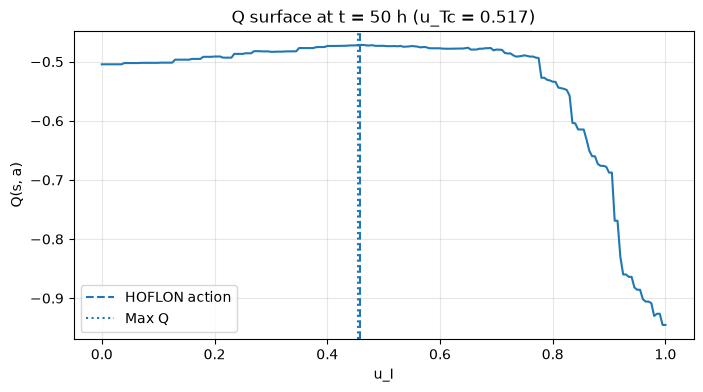

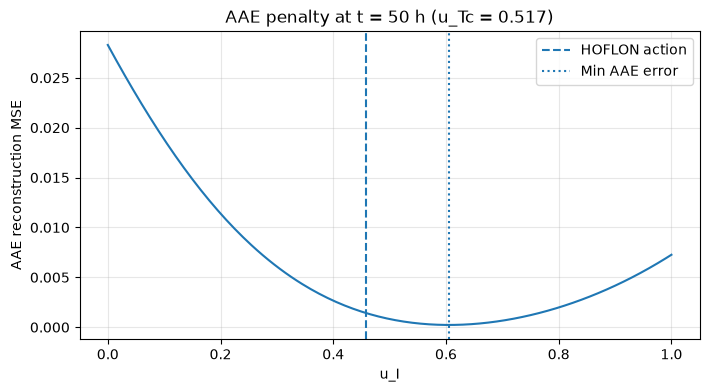

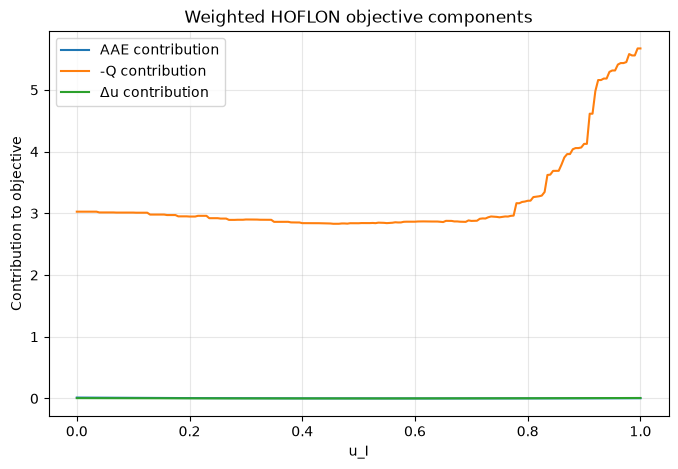

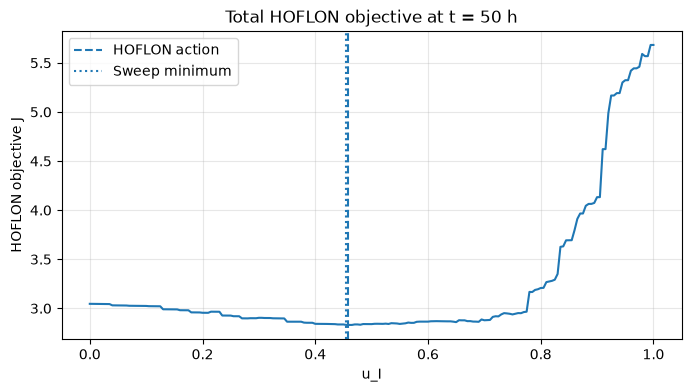

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from poly_reactor_env import PolymerisationEnv


# ============================================================
# SETTINGS
# ============================================================

SEED = 11
TARGET_HOUR = 50.0
N_POINTS = 201


# ============================================================
# 1. RUN HOFLON UNTIL THE TARGET TIME
# ============================================================

env = PolymerisationEnv(seed=SEED)

obs, info = env.reset(seed=SEED)
hoflon.reset()

target_obs = None
target_action = None
target_info = None

terminated = False
truncated = False

while not (terminated or truncated):

    action = hoflon(obs)

    current_hour = info["time_s"] / 3600.0

    if current_hour >= TARGET_HOUR:
        target_obs = obs.copy()
        target_action = action.copy()
        target_info = info.copy()
        break

    obs, reward, terminated, truncated, info = env.step(action)


# ============================================================
# 2. DISPLAY THE OPERATING POINT
# ============================================================

print("Operating point")
print("----------------")
print(f"Time       : {target_info['time_s']/3600:.1f} h")
print(f"P physical : {target_info['P']:.3f}")
print(f"T physical : {target_info['T']:.3f}")
print()
print("Scaled observation:")
print(target_obs)
print()
print(f"HOFLON action:")
print(f"u_I  = {target_action[0]:.4f}")
print(f"u_Tc = {target_action[1]:.4f}")


# ============================================================
# 3. FREEZE THE CONTROLLER MEMORY
#
# Important:
# objective() uses hoflon.u_prev for the Δu penalty.
# At this point hoflon.u_prev is the action selected at the
# operating point, which is exactly what we want.
# ============================================================

u_prev_fixed = hoflon.u_prev.copy()
u_tc_fixed = float(target_action[1])


# ============================================================
# 4. SWEEP u_I FROM 0 -> 1
# ============================================================

u_I_grid = np.linspace(0.0, 1.0, N_POINTS)

q_values = []
aae_values = []
du_values = []
total_values = []

cfg = hoflon.rto_config

for u_I in u_I_grid:

    action_test = np.array(
        [u_I, u_tc_fixed],
        dtype=np.float64
    )

    # Individual components
    q = hoflon._q_value(
        target_obs,
        action_test
    )

    aae = hoflon._aae_reconstruction_mse(
        target_obs,
        action_test
    )

    du = np.sum(
        (action_test - u_prev_fixed) ** 2
    )

    # Weighted contributions to actual objective
    q_term = cfg.f2 * (-q)
    aae_term = cfg.f1 * aae
    du_term = cfg.f3 * du

    total = (
        aae_term
        + q_term
        + du_term
    )

    q_values.append(q)
    aae_values.append(aae)
    du_values.append(du)
    total_values.append(total)


q_values = np.asarray(q_values)
aae_values = np.asarray(aae_values)
du_values = np.asarray(du_values)
total_values = np.asarray(total_values)


# ============================================================
# 5. FIND WHAT EACH COMPONENT PREFERS
# ============================================================

best_q_idx = np.argmax(q_values)
best_aae_idx = np.argmin(aae_values)
best_total_idx = np.argmin(total_values)

print("\nDiagnostic")
print("----------")

print(
    f"Q prefers u_I       = "
    f"{u_I_grid[best_q_idx]:.4f}"
)

print(
    f"AAE prefers u_I     = "
    f"{u_I_grid[best_aae_idx]:.4f}"
)

print(
    f"Objective prefers   = "
    f"{u_I_grid[best_total_idx]:.4f}"
)

print(
    f"Actual HOFLON u_I   = "
    f"{target_action[0]:.4f}"
)


# ============================================================
# 6. PLOT RAW Q
# ============================================================

plt.figure(figsize=(8, 4))

plt.plot(
    u_I_grid,
    q_values
)

plt.axvline(
    target_action[0],
    linestyle="--",
    label="HOFLON action"
)

plt.axvline(
    u_I_grid[best_q_idx],
    linestyle=":",
    label="Max Q"
)

plt.xlabel("u_I")
plt.ylabel("Q(s, a)")
plt.title(
    f"Q surface at t = {TARGET_HOUR:.0f} h "
    f"(u_Tc = {u_tc_fixed:.3f})"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()


# ============================================================
# 7. PLOT RAW AAE RECONSTRUCTION ERROR
# ============================================================

plt.figure(figsize=(8, 4))

plt.plot(
    u_I_grid,
    aae_values
)

plt.axvline(
    target_action[0],
    linestyle="--",
    label="HOFLON action"
)

plt.axvline(
    u_I_grid[best_aae_idx],
    linestyle=":",
    label="Min AAE error"
)

plt.xlabel("u_I")
plt.ylabel("AAE reconstruction MSE")

plt.title(
    f"AAE penalty at t = {TARGET_HOUR:.0f} h "
    f"(u_Tc = {u_tc_fixed:.3f})"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()


# ============================================================
# 8. PLOT ACTUAL WEIGHTED OBJECTIVE COMPONENTS
# ============================================================

aae_weighted = cfg.f1 * aae_values
q_weighted = cfg.f2 * (-q_values)
du_weighted = cfg.f3 * du_values

plt.figure(figsize=(8, 5))

plt.plot(
    u_I_grid,
    aae_weighted,
    label="AAE contribution"
)

plt.plot(
    u_I_grid,
    q_weighted,
    label="-Q contribution"
)

plt.plot(
    u_I_grid,
    du_weighted,
    label="Δu contribution"
)

plt.xlabel("u_I")
plt.ylabel("Contribution to objective")
plt.title("Weighted HOFLON objective components")

plt.grid(alpha=0.3)
plt.legend()
plt.show()


# ============================================================
# 9. PLOT FINAL OBJECTIVE
# ============================================================

plt.figure(figsize=(8, 4))

plt.plot(
    u_I_grid,
    total_values
)

plt.axvline(
    target_action[0],
    linestyle="--",
    label="HOFLON action"
)

plt.axvline(
    u_I_grid[best_total_idx],
    linestyle=":",
    label="Sweep minimum"
)

plt.xlabel("u_I")
plt.ylabel("HOFLON objective J")

plt.title(
    f"Total HOFLON objective at t = {TARGET_HOUR:.0f} h"
)

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [5]:
import pandas as pd

df = pd.read_csv("pid_dataset.csv")

cols = [
    "A", "I", "P", "R", "T",
    "err_P", "err_T",
    "int_err_P", "int_err_T",
    "u_I", "u_Tc"
]

print(
    df[cols].describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    ).T
)

             count          mean           std       min            1%  \
A          20000.0  4.561037e+00  2.023229e-01  4.031208  4.279595e+00   
I          20000.0  8.691858e-02  1.791367e-02  0.000000  1.747074e-02   
P          20000.0  9.461690e-01  1.944563e-01 -0.010671  3.912822e-02   
R          20000.0  1.465510e-08  2.657651e-09  0.000000  5.737189e-09   
T          20000.0  3.442174e-01  1.281887e-01  0.000000  1.346850e-01   
err_P      20000.0  5.383095e-02  1.944563e-01 -0.434099 -2.209303e-01   
err_T      20000.0 -4.333481e-02  1.281887e-01 -0.699117 -5.241682e-01   
int_err_P  20000.0  6.480631e+00  2.966015e+00  0.000000  0.000000e+00   
int_err_T  20000.0 -4.203773e-01  1.813229e-01 -1.000000 -8.730855e-01   
u_I        20000.0  6.727523e-01  1.785602e-01  0.000000  7.405836e-02   
u_Tc       20000.0  5.126264e-01  7.524555e-03  0.501310  5.047039e-01   

                     5%           50%           95%           99%  \
A          4.382969e+00  4.512203e+00  4.9

TRAINING DATASET
----------------
count    20000.000000
mean         6.480631
std          2.966015
min          0.000000
1%           0.000000
5%           1.543368
50%          6.371226
95%         11.849533
99%         13.727086
max         14.390507
Name: int_err_P, dtype: float64

Training maximum int_err_P = 14.3905

DEPLOYMENT STATE
----------------
Time      = 50.0 h
P         = 82.815
T         = 349.792
err_P     = 0.1718
int_err_P = 45.1655
Ratio to training maximum = 3.14x

Q OPTIMUM VS int_err_P
----------------------
int_err_P =   0.0  ->  best u_I = 0.480  |  max Q = -0.59910
int_err_P =   5.0  ->  best u_I = 0.455  |  max Q = -0.51675
int_err_P =  10.0  ->  best u_I = 0.455  |  max Q = -0.47138
int_err_P =  14.0  ->  best u_I = 0.455  |  max Q = -0.47168
int_err_P =  20.0  ->  best u_I = 0.455  |  max Q = -0.47168
int_err_P =  30.0  ->  best u_I = 0.455  |  max Q = -0.47168
int_err_P =  45.0  ->  best u_I = 0.455  |  max Q = -0.47168


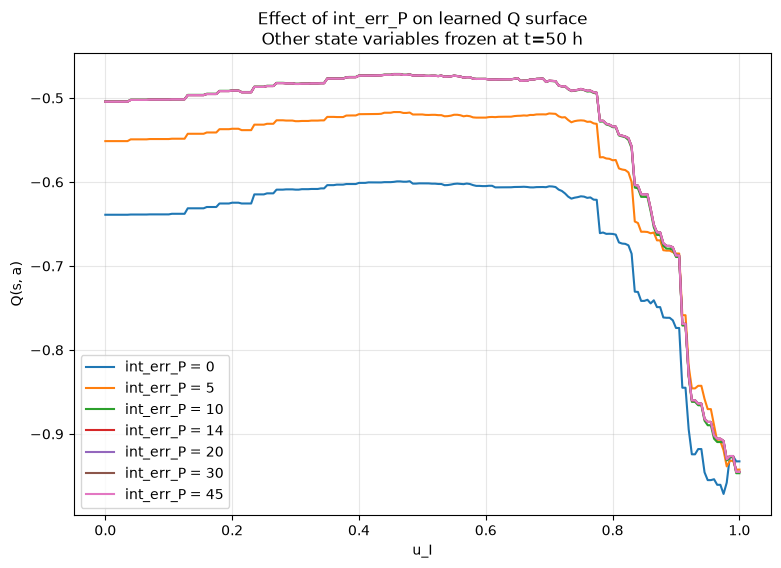

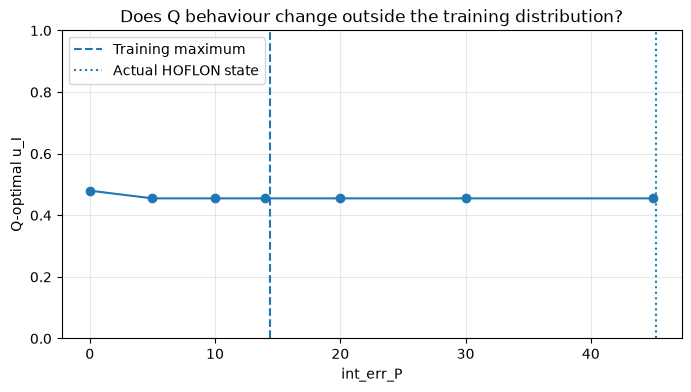

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from poly_reactor_env import PolymerisationEnv


# ============================================================
# SETTINGS
# ============================================================

DATASET_PATH = "pid_dataset.csv"
SEED = 11
TARGET_HOUR = 50.0

INT_ERR_TEST_VALUES = [
    0.0,
    5.0,
    10.0,
    14.0,   # approximately training maximum
    20.0,
    30.0,
    45.0,
]

N_ACTIONS = 201


# ============================================================
# 1. DATASET RANGE
# ============================================================

df = pd.read_csv(DATASET_PATH)

print("TRAINING DATASET")
print("----------------")

print(
    df["int_err_P"].describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    )
)

training_max = df["int_err_P"].max()

print()
print(f"Training maximum int_err_P = {training_max:.4f}")


# ============================================================
# 2. RUN CURRENT HOFLON TO 50 h
# ============================================================

env = PolymerisationEnv(seed=SEED)

obs, info = env.reset(seed=SEED)
hoflon.reset()

terminated = False
truncated = False

while not (terminated or truncated):

    current_hour = info["time_s"] / 3600.0

    if current_hour >= TARGET_HOUR:
        target_obs = obs.copy()
        target_info = info.copy()
        break

    action = hoflon(obs)

    obs, reward, terminated, truncated, info = env.step(action)


print("\nDEPLOYMENT STATE")
print("----------------")

print(f"Time      = {TARGET_HOUR:.1f} h")
print(f"P         = {target_info['P']:.3f}")
print(f"T         = {target_info['T']:.3f}")

print(f"err_P     = {target_obs[5]:.4f}")
print(f"int_err_P = {target_obs[7]:.4f}")

print(
    f"Ratio to training maximum = "
    f"{target_obs[7] / training_max:.2f}x"
)


# ============================================================
# 3. FREEZE EVERYTHING EXCEPT int_err_P AND u_I
# ============================================================

u_tc_fixed = float(hoflon.u_prev[1])

u_I_grid = np.linspace(
    0.0,
    1.0,
    N_ACTIONS
)


# ============================================================
# 4. Q SWEEP FOR DIFFERENT int_err_P VALUES
# ============================================================

results = {}

for int_err_value in INT_ERR_TEST_VALUES:

    test_obs = target_obs.copy()

    # int_err_P is index 7 in canonical observation
    test_obs[7] = int_err_value

    q_values = []

    for u_I in u_I_grid:

        action = np.array(
            [u_I, u_tc_fixed],
            dtype=np.float64
        )

        q = hoflon._q_value(
            test_obs,
            action
        )

        q_values.append(q)

    q_values = np.asarray(q_values)

    best_idx = np.argmax(q_values)

    results[int_err_value] = {
        "q": q_values,
        "best_uI": u_I_grid[best_idx],
        "best_Q": q_values[best_idx],
    }


# ============================================================
# 5. PRINT OPTIMUM AS int_err_P CHANGES
# ============================================================

print("\nQ OPTIMUM VS int_err_P")
print("----------------------")

for value in INT_ERR_TEST_VALUES:

    result = results[value]

    print(
        f"int_err_P = {value:>5.1f}  ->  "
        f"best u_I = {result['best_uI']:.3f}  |  "
        f"max Q = {result['best_Q']:.5f}"
    )


# ============================================================
# 6. PLOT Q SURFACES
# ============================================================

plt.figure(figsize=(9, 6))

for value in INT_ERR_TEST_VALUES:

    plt.plot(
        u_I_grid,
        results[value]["q"],
        label=f"int_err_P = {value:g}"
    )

plt.xlabel("u_I")
plt.ylabel("Q(s, a)")

plt.title(
    f"Effect of int_err_P on learned Q surface\n"
    f"Other state variables frozen at t={TARGET_HOUR:.0f} h"
)

plt.grid(alpha=0.3)
plt.legend()

plt.show()


# ============================================================
# 7. PLOT PREFERRED u_I AGAINST int_err_P
# ============================================================

int_values = np.array(
    INT_ERR_TEST_VALUES
)

best_actions = np.array([
    results[value]["best_uI"]
    for value in INT_ERR_TEST_VALUES
])

plt.figure(figsize=(8, 4))

plt.plot(
    int_values,
    best_actions,
    marker="o"
)

plt.axvline(
    training_max,
    linestyle="--",
    label="Training maximum"
)

plt.axvline(
    target_obs[7],
    linestyle=":",
    label="Actual HOFLON state"
)

plt.xlabel("int_err_P")
plt.ylabel("Q-optimal u_I")

plt.title(
    "Does Q behaviour change outside the training distribution?"
)

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.show()